# 0. Imports

In [1]:
import matplotlib.pyplot as plt  # Plot training results
import torch                     # Tensors and training
from torch import nn             # Neural network layers and loss functions
from torch_geometric.datasets import Planetoid  # Load Cora

from copy import deepcopy

import json
from pathlib import Path

import sys
sys.path.append("..")  # Makes the project folder importable


c:\Users\Pablo\Desktop\Universidad\Master\Thesis\01_gnn_cora\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


# 1. Load the data

In [2]:
dataset = Planetoid(root="../data", name="Cora")
graph = dataset[0]

In [3]:
# Training data
X_train = graph.x[graph.train_mask]
y_train = graph.y[graph.train_mask]

# Validation data
X_val = graph.x[graph.val_mask]
y_val = graph.y[graph.val_mask]

# Test data
X_test = graph.x[graph.test_mask]
y_test = graph.y[graph.test_mask]

X_train.shape, X_val.shape, X_test.shape

(torch.Size([140, 1433]), torch.Size([500, 1433]), torch.Size([1000, 1433]))

# 2. GNN model

In [4]:
from src.models import GNN

seed = 42
torch.manual_seed(seed)

model = GNN(
    input_dim=dataset.num_node_features,
    hidden_dim=64,
    num_classes=dataset.num_classes,
)

print(model)

GNN(
  (conv1): GCNConv(1433, 64)
  (conv2): GCNConv(64, 7)
)


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 200

best_val_accuracy = -1.0
best_state = None
best_epoch = None

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

for epoch in range(1, epochs + 1):
    # Training: predict all nodes, compute loss on training nodes only.
    model.train()
    optimizer.zero_grad()

    logits = model(graph.x, graph.edge_index)
    loss = criterion(
        logits[graph.train_mask],
        graph.y[graph.train_mask],
    )

    loss.backward()
    optimizer.step()

    # Evaluate the updated model.
    model.eval()
    with torch.no_grad():
        logits = model(graph.x, graph.edge_index)

        train_loss = criterion(
            logits[graph.train_mask],
            graph.y[graph.train_mask],
        ).item()

        val_loss = criterion(
            logits[graph.val_mask],
            graph.y[graph.val_mask],
        ).item()

        predictions = logits.argmax(dim=1)

        train_accuracy = (
            predictions[graph.train_mask] == graph.y[graph.train_mask]
        ).float().mean().item()

        val_accuracy = (
            predictions[graph.val_mask] == graph.y[graph.val_mask]
        ).float().mean().item()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_state = deepcopy(model.state_dict())
        best_epoch = epoch

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"Val accuracy: {val_accuracy:.1%}"
        )

print(
    f"Best epoch: {best_epoch} | "
    f"Val accuracy: {best_val_accuracy:.1%}"
)

Epoch   1 | Train loss: 1.6775 | Val loss: 1.8351 | Val accuracy: 56.2%
Epoch  20 | Train loss: 0.0032 | Val loss: 0.8695 | Val accuracy: 77.6%
Epoch  40 | Train loss: 0.0003 | Val loss: 1.0501 | Val accuracy: 77.4%
Epoch  60 | Train loss: 0.0001 | Val loss: 1.0933 | Val accuracy: 77.6%
Epoch  80 | Train loss: 0.0001 | Val loss: 1.1068 | Val accuracy: 77.4%
Epoch 100 | Train loss: 0.0001 | Val loss: 1.1136 | Val accuracy: 77.4%
Epoch 120 | Train loss: 0.0001 | Val loss: 1.1177 | Val accuracy: 77.2%
Epoch 140 | Train loss: 0.0001 | Val loss: 1.1209 | Val accuracy: 77.4%
Epoch 160 | Train loss: 0.0001 | Val loss: 1.1237 | Val accuracy: 77.4%
Epoch 180 | Train loss: 0.0001 | Val loss: 1.1263 | Val accuracy: 77.4%
Epoch 200 | Train loss: 0.0001 | Val loss: 1.1291 | Val accuracy: 77.6%
Best epoch: 8 | Val accuracy: 79.4%


In [6]:
model.load_state_dict(best_state)
model.eval()

with torch.no_grad():
    logits = model(graph.x, graph.edge_index)

    test_predictions = logits[graph.test_mask].argmax(dim=1)
    test_accuracy = (
        test_predictions == graph.y[graph.test_mask]
    ).float().mean().item()

print(f"Test accuracy: {test_accuracy:.1%}")

Test accuracy: 79.9%


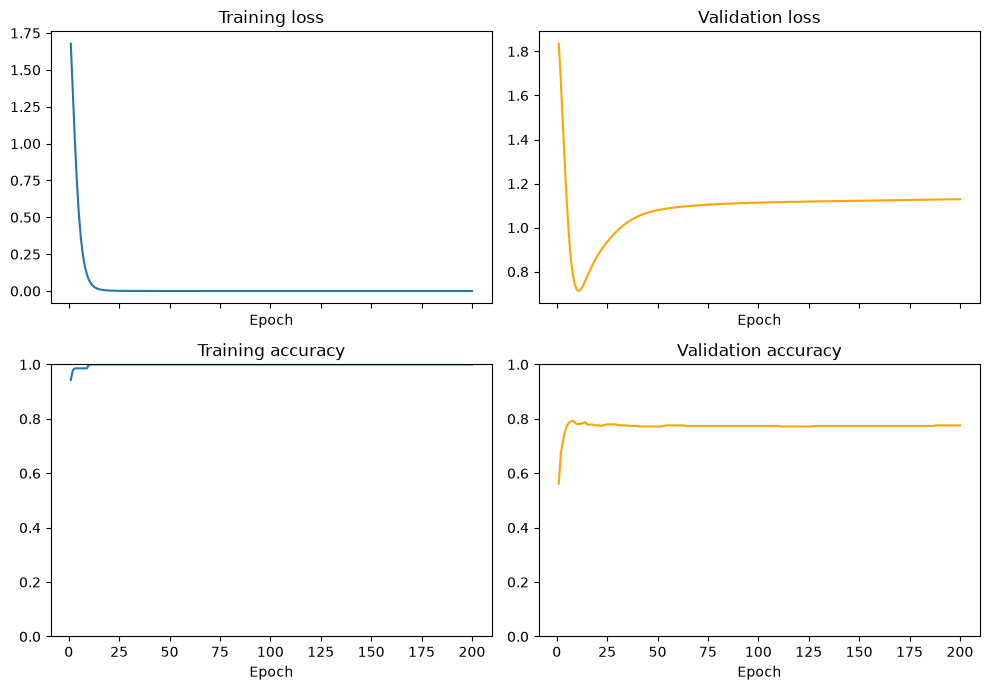

In [7]:
results_dir = Path("../results") / type(model).__name__
results_dir.mkdir(parents=True, exist_ok=True)

results = {
    "model": type(model).__name__,
    "learning_rate": optimizer.param_groups[0]["lr"],
    "best_epoch": best_epoch,
    "val_accuracy": best_val_accuracy,
    "test_accuracy": test_accuracy,
}

file_path = results_dir / f"{results['model']}.json"

file_path.write_text(json.dumps(results, indent=2), encoding="utf-8")

epoch_numbers = range(1, len(train_losses) + 1)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)

axes[0, 0].plot(epoch_numbers, train_losses)
axes[0, 0].set_title("Training loss")

axes[0, 1].plot(epoch_numbers, val_losses, color="orange")
axes[0, 1].set_title("Validation loss")

axes[1, 0].plot(epoch_numbers, train_accuracies)
axes[1, 0].set_title("Training accuracy")
axes[1, 0].set_ylim(0, 1)

axes[1, 1].plot(epoch_numbers, val_accuracies, color="orange")
axes[1, 1].set_title("Validation accuracy")
axes[1, 1].set_ylim(0, 1)

for ax in axes.flat:
    ax.set_xlabel("Epoch")

plt.tight_layout()
fig.savefig(results_dir / "training.png", dpi=150)
plt.show()